# SNR-PER-010 추론 및 성능평가
제공된 사전학습 모델로 MOT20-01/02/03/05의 8,931프레임을 추론하고, 네 시퀀스 MOTA의 산술평균을 계산합니다.
판정 조건은 IoU 0.1, 목표는 평균 MOTA 80% 이상입니다. 모델 가중치와 최종 추적·후처리 설정을 고정하여 실행합니다.

In [1]:
import json
import os
from pathlib import Path
import subprocess
import sys
import time
from IPython.display import Image, clear_output, display

package=Path.cwd().resolve()
assert (package/'run_inference.py').is_file()
workspace=Path(os.environ.get('SNR010_WORK_ROOT',str(package/'workspace'))).resolve()
run_name=os.environ.get('SNR010_RUN_NAME','inference')
cache_source=os.environ.get('SNR010_BACKBONE_CACHE')
(workspace/'logs').mkdir(parents=True,exist_ok=True)
print('Python:',sys.executable)
print('Workspace:',workspace)
print('Frozen backbone cache:',cache_source or 'disabled')


Python: /opt/snr010-env/bin/python
Workspace: /home/jovyan/snr-per-010/example/snr_per_010/workspace
Frozen backbone cache: /home/jovyan/snr-per-010/fold01-canonical-precision


In [2]:
subprocess.run([sys.executable,str(package/'download_dataset.py'),'--workspace',str(workspace)],check=True)


DATASET_DOWNLOAD https://motchallenge.net/data/MOT20.zip offset_bytes 0 total_bytes 5028926248
DOWNLOAD_PROGRESS_MIB 256.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 512.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 768.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 1024.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 1280.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 1536.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 1792.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 2048.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 2304.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 2560.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 2816.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 3072.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 3328.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 3584.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 3840.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 4096.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 4352.0 of 4796.0
DOWNLOAD_PROGRESS_MIB 4608.0 of 4796.0
DATASET_ARCHIVE_DOWNLOADED 5028926248
EXTRACTED_IMAGES 500 of 8931
EXTRACTED_IMAGES 1000 of 8931
EXTRACTED_IMAGES 1500 of 8931
EXTRACTED_IMAGES 2000 of 8931
EXTRACTED_IMAGES 2500 of 8931
EXTRACTED_IMAGES 30

CompletedProcess(args=['/opt/snr010-env/bin/python', '/home/jovyan/snr-per-010/example/snr_per_010/download_dataset.py', '--workspace', '/home/jovyan/snr-per-010/example/snr_per_010/workspace'], returncode=0)

In [3]:
manifest=json.loads((package/'MODEL_MANIFEST.json').read_text())
print('Model and configuration files:',len(manifest))
print('Total bytes:',sum(item['bytes'] for item in manifest))
print('SHA-256 validation runs before inference.')


Model and configuration files: 60
Total bytes: 961510077
SHA-256 validation runs before inference.


In [4]:
command=[sys.executable,str(package/'run_inference.py'),'--workspace',str(workspace),'--run-name',run_name]
if cache_source:
    command.extend(['--reuse-backbone-cache',cache_source])
log_path=workspace/'logs'/f'{run_name}.log'
with log_path.open('w') as stream:
    process=subprocess.Popen(command,stdout=stream,stderr=subprocess.STDOUT)
    while process.poll() is None:
        clear_output(wait=True)
        root=workspace/'runs'/run_name
        for name in ['progress.json','remaining-progress.json','remaining-detector-progress.json']:
            path=root/name
            if path.exists():
                state=json.loads(path.read_text())
                keys=['stage','current_sequence','sequence','mode','frames_complete','frames_expected','updated_at']
                print(name,json.dumps({key:state[key] for key in keys if key in state},ensure_ascii=False))
        print('Log:',log_path)
        time.sleep(15)
    if process.returncode:
        raise RuntimeError(log_path.read_text()[-6000:])
print('Inference and evaluation complete.')


progress.json {"stage": "complete", "frames_complete": 429, "frames_expected": 429, "updated_at": "2026-10-22T03:36:52.862574+00:00"}
remaining-progress.json {"stage": "available_sequences_finished", "current_sequence": "MOT20-05", "updated_at": "2026-10-22T04:13:59.885124+00:00"}
Log: /home/jovyan/snr-per-010/example/snr_per_010/workspace/logs/recorded-inference.log
Inference and evaluation complete.


,sequence,mota_percent,fp,fn,idsw,gt,idf1_percent
0,MOT20-01,81.137393,1150,2395,203,19870,69.390830
1,MOT20-02,75.939952,17139,18585,1507,154742,51.765691
2,MOT20-03,81.220948,22352,35744,806,313658,74.050534
3,MOT20-05,81.745943,46939,62742,8303,646344,59.151764


4-sequence mean MOTA: 80.011059%
Target: PASS


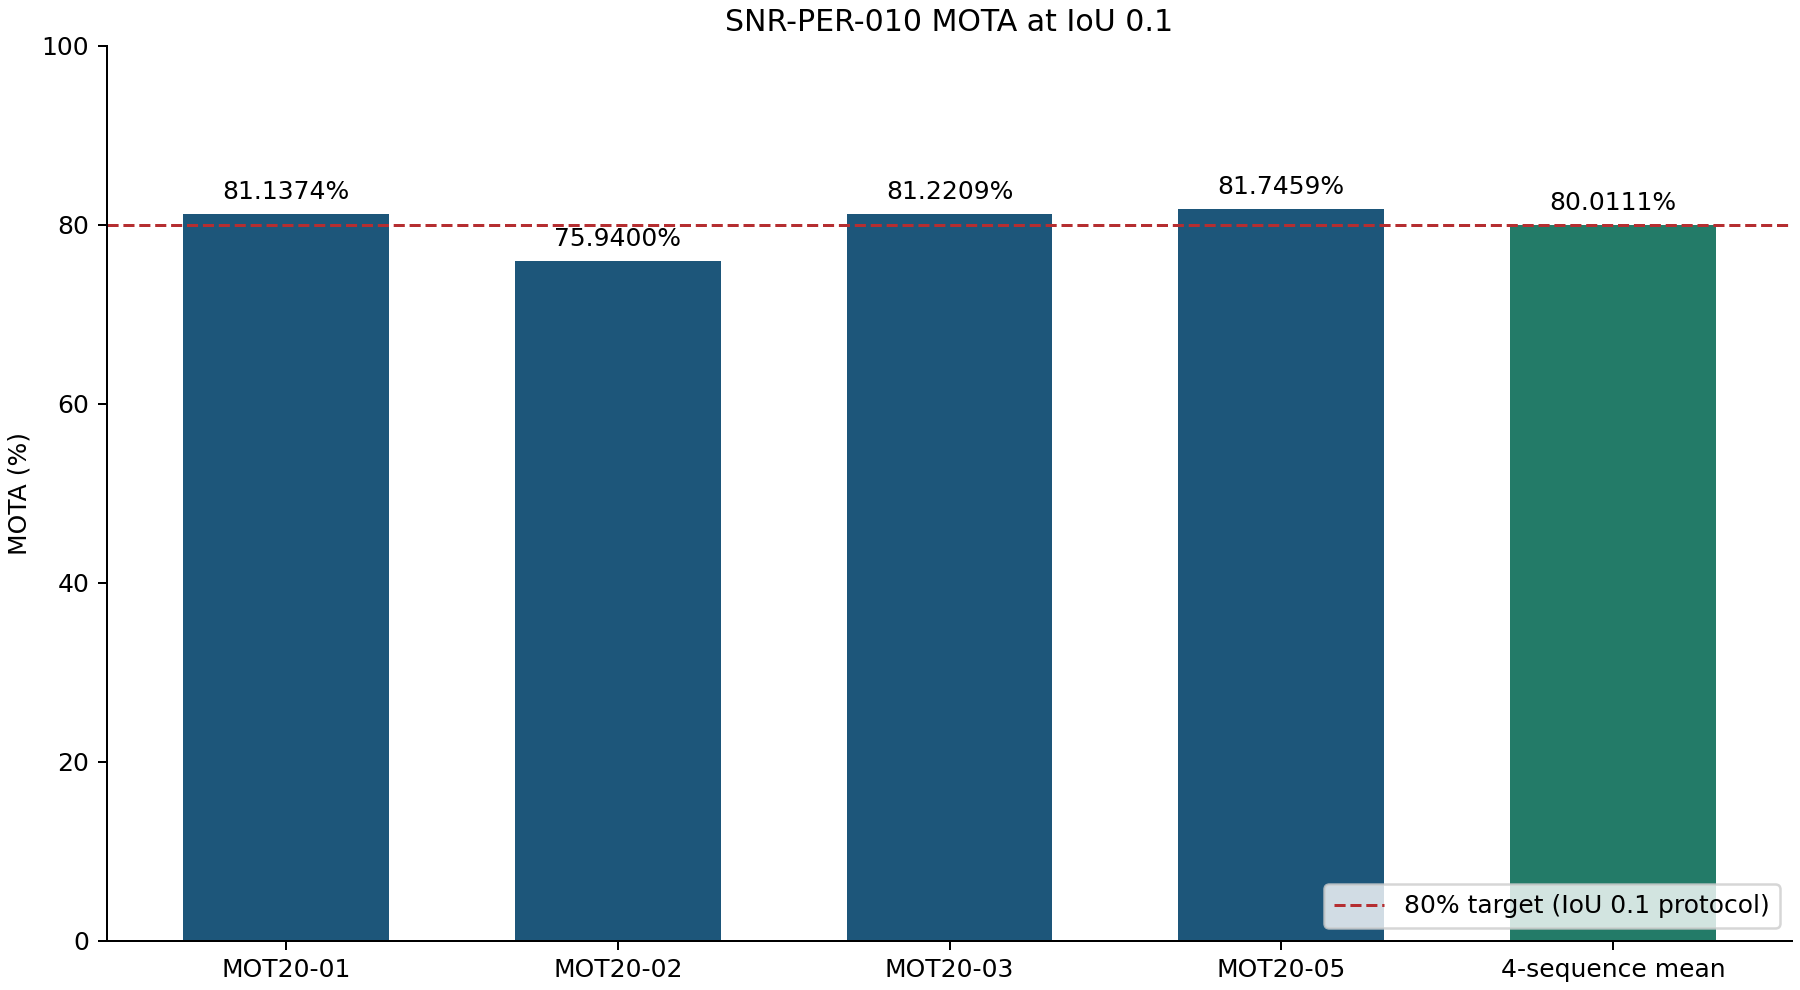

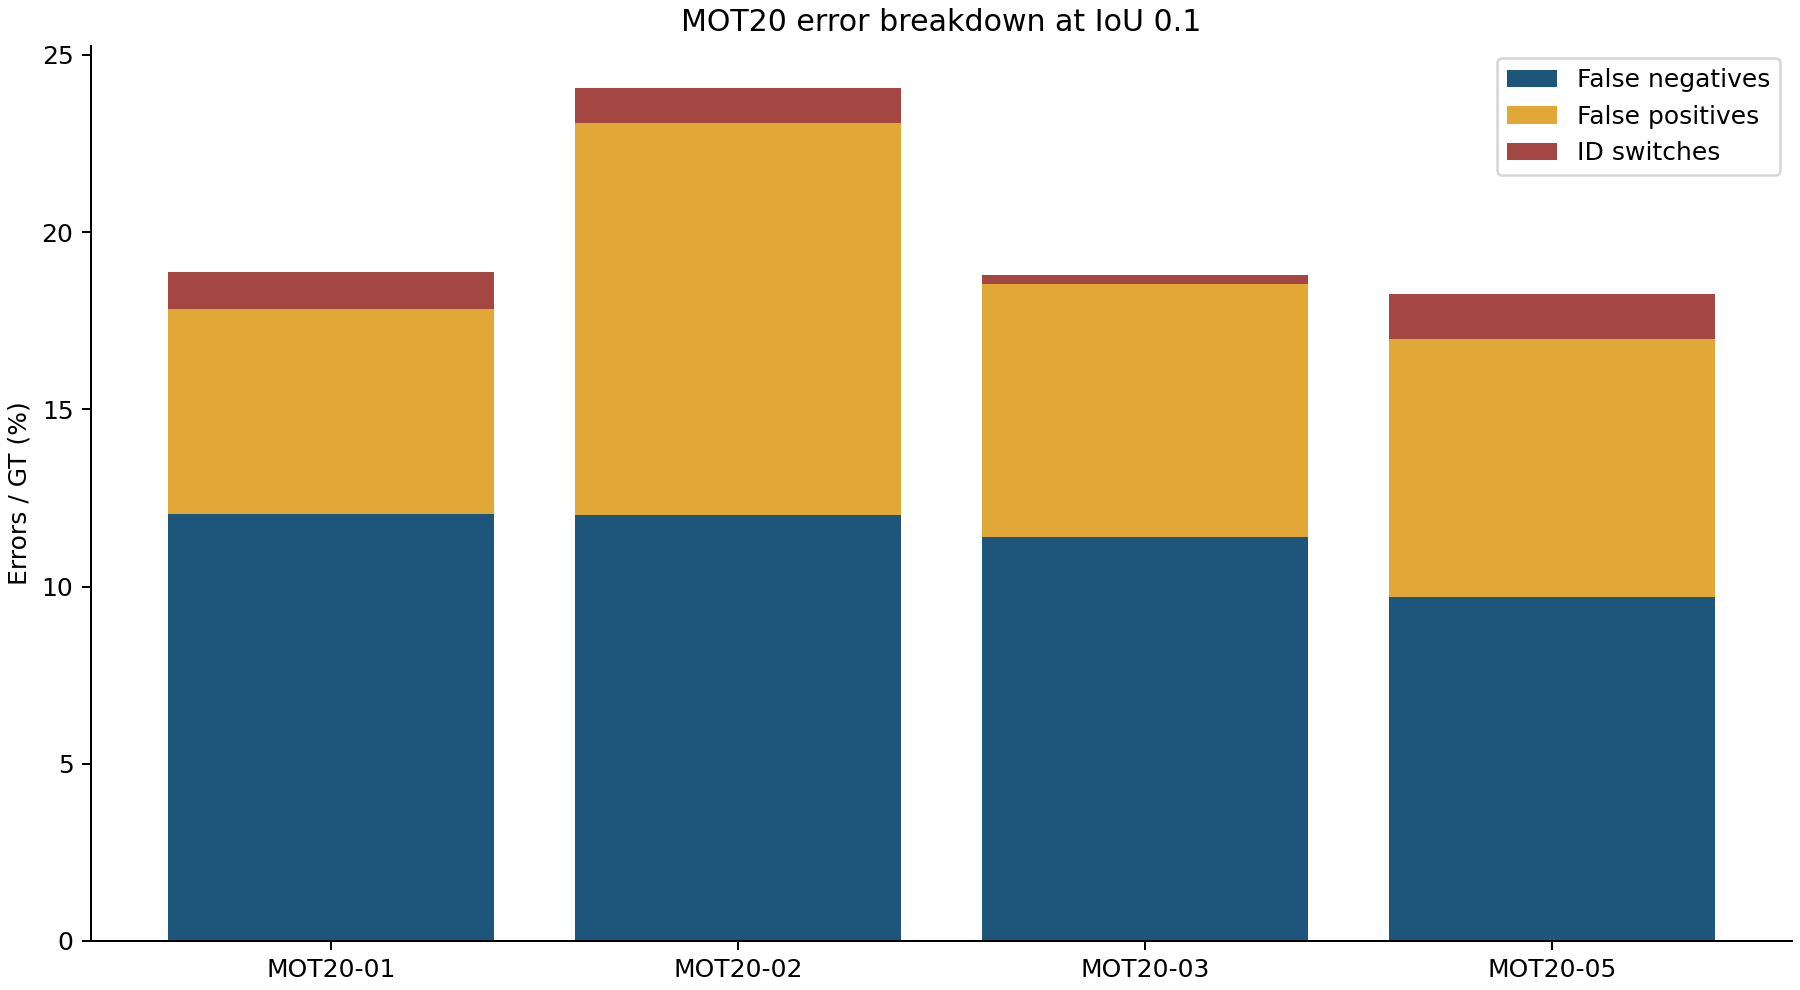

In [5]:
import pandas as pd

result=workspace/'results'/run_name
metrics=json.loads((result/'evaluation/metrics.json').read_text())
primary=next(item for item in metrics['evaluations'] if item['match_iou']==0.1)
display(pd.DataFrame(primary['folds']))
print(f"4-sequence mean MOTA: {primary['macro_mota_percent']:.6f}%")
print('Target:', 'PASS' if primary['macro_mota_percent']>=80 else 'FAIL')
display(Image(filename=str(result/'charts/mota_comparison.png')))
display(Image(filename=str(result/'charts/error_breakdown.png')))
